# 1. Portada e introducción

**Micro proyecto 2 — Generación de código con Transformers**
Curso: Modelos Avanzados de Procesamiento de Lenguaje Natural

**Parte: modelo GPT desde cero**

## Resumen

Este notebook contiene la configuración 1 de las cinco que compara el proyecto: un Transformer *decoder-only* (tipo GPT)
implementado en PyTorch y entrenado desde cero para generar código Python. Se usa el corpus `codeparrot/codeparrot-clean`:
8.000 archivos de entre 1.000 y 2.000 caracteres, tokenizados con el tokenizador BPE de SmolLM2 (vocabulario de 49.152 tokens),
segmentados en secuencias de 256 tokens y repartidos en 6.400 / 800 / 800 archivos (entrenamiento / validación / prueba).
De la familia SmolLM2 solo se usa el **tokenizador**: no se carga ningún peso pre-entrenado.

Las configuraciones 2 a 5 (SmolLM2-135M y SmolLM2-360M, pre-entrenados y con finetuning completo) se integran en la sección 7.
Para que la perplejidad sea comparable, todas usan el mismo tokenizador, el mismo split, los mismos bloques de 256 tokens y
las mismas funciones de evaluación de este notebook.

Métricas sobre el conjunto de prueba: **perplejidad** (principal), **exactitud top-1 / top-5** del siguiente token y
**porcentaje de validez sintáctica** de las generaciones verificada con `ast.parse` (secundaria). La función de generación
es un bucle autorregresivo propio (sin `model.generate()`).

# 2. Librerías

In [1]:
import ast
import gc
import json
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from transformers import AutoTokenizer

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

# Dispositivo: GPU NVIDIA (Colab), GPU Apple (MPS) o CPU
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

# Precisión mixta: bf16 si está soportado (no necesita GradScaler); en GPUs tipo T4 se usa fp16 + GradScaler
if device == 'cuda':
    AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
elif device == 'mps':
    AMP_DTYPE = torch.bfloat16
else:
    AMP_DTYPE = torch.bfloat16
USE_AMP = device in ('cuda', 'mps')
USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16

# Carpetas propias de este notebook (al integrar se pueden unificar con las del finetuning)
CKPT_DIR = 'checkpoints_desde_cero'
RESULTS_DIR = 'results_desde_cero'
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('torch', torch.__version__, '| device:', device, '| AMP:', USE_AMP, AMP_DTYPE, '| GradScaler:', USE_SCALER)


LOG_FILE = os.path.join(RESULTS_DIR, 'log.txt')
def log(msg):
    # Imprime y guarda el mensaje (permite seguir el progreso de entrenamientos largos)
    print(msg, flush=True)
    with open(LOG_FILE, 'a') as f:
        f.write(msg + '\n')


def free_memory():
    # Libera memoria de la GPU entre modelos
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    elif device == 'mps':
        torch.mps.empty_cache()

c:\Users\USUARIO\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.11.0+cu128 | device: cuda | AMP: True torch.bfloat16 | GradScaler: False


# 3. Carga del dataset y exploración

Se carga `codeparrot/codeparrot-clean` en modo *streaming* (sin descargar el corpus completo). Mientras se recorre el
stream se registra la longitud de todos los archivos vistos, para describir la distribución original antes del filtro.

In [2]:
N_EXAMPLES = 8000
MIN_CHARS, MAX_CHARS = 1000, 2000  # filtro de longitud obligatorio

# El corpus recolectado se guarda en disco para que una re-ejecución no dependa de la red;
# si el archivo no existe, se recorre el stream (resultado idéntico: mismo orden del stream y mismo filtro)
CORPUS_CACHE = os.path.join('data', 'corpus_codeparrot_8000.json')
t0 = time.time()
if os.path.exists(CORPUS_CACHE):
    with open(CORPUS_CACHE) as f:
        cached = json.load(f)
    corpus, seen_lengths = cached['corpus'], cached['seen_lengths']
    print('Corpus cargado desde', CORPUS_CACHE)
else:
    stream = load_dataset('codeparrot/codeparrot-clean', split='train', streaming=True)
    corpus = []
    seen_lengths = []  # longitud de todos los archivos recorridos (antes del filtro)
    for example in stream:
        code_text = example['content']  # 'content' contiene el código del archivo
        seen_lengths.append(len(code_text))
        if not (MIN_CHARS <= len(code_text) <= MAX_CHARS):
            continue  # se descartan ejemplos fuera del rango
        corpus.append(code_text)
        if len(corpus) % 1000 == 0:
            print(f'  {len(corpus):,} ejemplos ({time.time() - t0:.0f}s)', flush=True)
        if len(corpus) >= N_EXAMPLES:
            break
    os.makedirs('data', exist_ok=True)
    with open(CORPUS_CACHE, 'w') as f:
        json.dump({'corpus': corpus, 'seen_lengths': seen_lengths}, f)

print(f'Archivos recorridos: {len(seen_lengths):,} | conservados: {len(corpus):,} '
      f'({len(corpus) / len(seen_lengths):.1%}) | {time.time() - t0:.0f}s')

  1,000 ejemplos (6s)
  2,000 ejemplos (7s)
  3,000 ejemplos (9s)
  4,000 ejemplos (11s)
  5,000 ejemplos (13s)
  6,000 ejemplos (14s)
  7,000 ejemplos (16s)
  8,000 ejemplos (18s)
Archivos recorridos: 38,071 | conservados: 8,000 (21.0%) | 18s


       recorridos  conservados
count     38071.0       8000.0
mean      10041.0       1477.0
std       20074.0        284.0
min         820.0       1002.0
25%        2245.0       1220.0
50%        4521.0       1463.0
75%       10225.0       1715.0
max      749187.0       2000.0


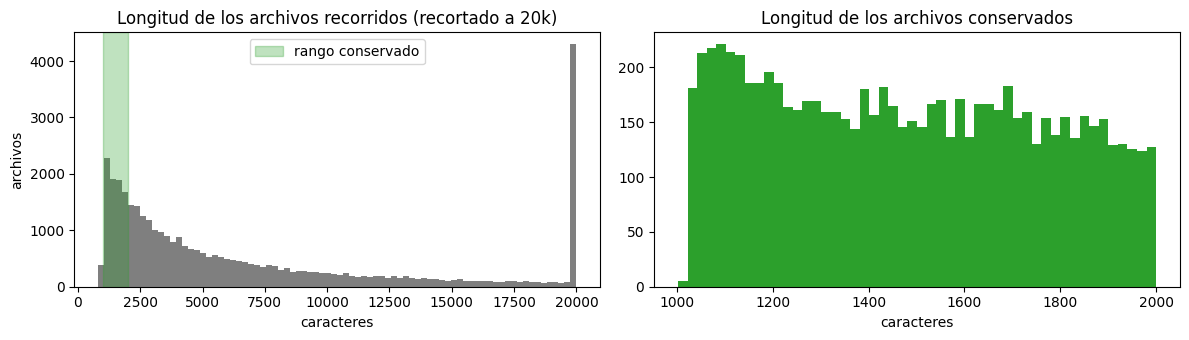

In [3]:
seen = np.array(seen_lengths)
kept = np.array([len(c) for c in corpus])
print(pd.DataFrame({'recorridos': pd.Series(seen).describe(), 'conservados': pd.Series(kept).describe()}).round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.clip(seen, 0, 20000), bins=80, color='tab:gray')
axes[0].axvspan(MIN_CHARS, MAX_CHARS, color='tab:green', alpha=0.3, label='rango conservado')
axes[0].set(title='Longitud de los archivos recorridos (recortado a 20k)', xlabel='caracteres', ylabel='archivos')
axes[0].legend()
axes[1].hist(kept, bins=50, color='tab:green')
axes[1].set(title='Longitud de los archivos conservados', xlabel='caracteres')
plt.tight_layout()
plt.show()

In [4]:
# Algunas estadísticas adicionales del corpus filtrado
n_lines = np.array([c.count('\n') + 1 for c in corpus])
has_def = np.mean(['def ' in c for c in corpus])
has_class = np.mean(['class ' in c for c in corpus])
def parses(src):
    try:
        ast.parse(src)
        return True
    except Exception:
        return False
py3_valid = np.mean([parses(c) for c in corpus])
print(f'Líneas por archivo: media {n_lines.mean():.1f}, mediana {np.median(n_lines):.0f}')
print(f'Archivos con funciones: {has_def:.1%} | con clases: {has_class:.1%}')
print(f'Archivos completos sintácticamente válidos en Python 3 (ast.parse): {py3_valid:.1%}')
print('\n=== Ejemplo de archivo ===\n')
print(corpus[0][:800])

Líneas por archivo: media 47.2, mediana 46
Archivos con funciones: 72.2% | con clases: 49.8%
Archivos completos sintácticamente válidos en Python 3 (ast.parse): 90.7%

=== Ejemplo de archivo ===

from contextlib import contextmanager
from datetime import datetime
from inspect import isclass

from celery import chord, group
from celery_once import QueueOnce
from celery.schedules import crontab
from celery.utils.log import get_task_logger
from sqlalchemy.orm.attributes import flag_modified

# from pipet import celery
from pipet.models import db, Organization
from pipet.sources.zendesk import ZendeskAccount
from pipet.sources.zendesk.models import (
    Base,
    CLASS_REGISTRY,
)


logger = get_task_logger(__name__)


# @celery.task(base=QueueOnce, once={'graceful': True})
def sync(account_id):
    with app.app_context():
        account = ZendeskAccount.query.get(account_id)
        session = account.organization.create_session()

        for cls in [m for n, m in CLASS_REGISTRY.ite


# 4. Preprocesamiento

- El filtro de longitud (1.000–2.000 caracteres) y el máximo de 8.000 ejemplos ya se aplicaron al recorrer el stream.
- Se tokeniza con el tokenizador de SmolLM2 (el 135M y el 360M comparten exactamente el mismo; se verifica).
- Cada archivo termina con el token `<|endoftext|>` como separador de documentos; luego, **dentro de cada partición**,
  los archivos se concatenan y se segmentan en bloques de 256 tokens (el bloque final incompleto se descarta).
  Así ningún bloque mezcla archivos de particiones distintas.

c:\Users\USUARIO\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USUARIO\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM2-360M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tamaño del vocabulario: 49152 | EOS: '<|endoftext|>' 0
Tokens por archivo: media 433, min 199, max 1358 | caracteres por token: 3.41 | total: 3,461,031 tokens


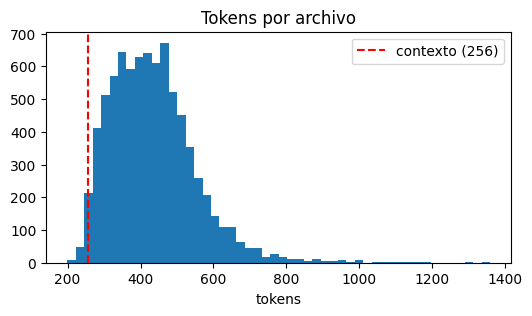

['from', 'Ġcontext', 'lib', 'Ġimport', 'Ġcontext', 'manager', 'Ċ', 'from', 'Ġdatetime', 'Ġimport', 'Ġdatetime', 'Ċ', 'from', 'Ġinspect', 'Ġimport', 'Ġis', 'class', 'Ċ', 'Ċ', 'from', 'Ġcelery', 'Ġimport', 'Ġchord', ',', 'Ġgroup', 'Ċ', 'from', 'Ġcelery', '_', 'once', 'Ġimport', 'ĠQueue', 'Once', 'Ċ', 'from', 'Ġcelery', '.', 'sched', 'ules', 'Ġimport']


In [5]:
CONTEXT_LEN = 256
tokenizer = AutoTokenizer.from_pretrained('HuggingFaceTB/SmolLM2-135M')
tokenizer_360 = AutoTokenizer.from_pretrained('HuggingFaceTB/SmolLM2-360M')
assert tokenizer.get_vocab() == tokenizer_360.get_vocab(), 'Los tokenizadores deberían ser idénticos'
del tokenizer_360

VOCAB_SIZE = tokenizer.vocab_size
EOS_ID = tokenizer.eos_token_id
print('Tamaño del vocabulario:', VOCAB_SIZE, '| EOS:', repr(tokenizer.eos_token), EOS_ID)

tokenized = [tokenizer(c)['input_ids'] + [EOS_ID] for c in corpus]
tok_lens = np.array([len(t) for t in tokenized])
print(f'Tokens por archivo: media {tok_lens.mean():.0f}, min {tok_lens.min()}, max {tok_lens.max()} '
      f'| caracteres por token: {kept.sum() / tok_lens.sum():.2f} | total: {tok_lens.sum():,} tokens')

plt.figure(figsize=(6, 3))
plt.hist(tok_lens, bins=50)
plt.axvline(CONTEXT_LEN, color='red', ls='--', label='contexto (256)')
plt.title('Tokens por archivo'); plt.xlabel('tokens'); plt.legend(); plt.show()

print(tokenizer.convert_ids_to_tokens(tokenized[0][:40]))

In [6]:
def make_blocks(token_lists, block_size=CONTEXT_LEN):
    # Concatena los archivos tokenizados y los segmenta en bloques de tamaño fijo
    flat = torch.tensor([t for toks in token_lists for t in toks], dtype=torch.long)
    n_blocks = len(flat) // block_size
    return flat[:n_blocks * block_size].view(n_blocks, block_size)

# 5. Split train / validación / prueba

Se barajan los 8.000 archivos con semilla fija y se reparten 6.400 / 800 / 800. El split es a nivel de archivo (antes de
segmentar), de modo que ningún archivo aparece en dos particiones.

In [7]:
idx = np.random.RandomState(SEED).permutation(len(corpus))
train_idx, val_idx, test_idx = idx[:6400], idx[6400:7200], idx[7200:8000]

train_code = [corpus[i] for i in train_idx]
val_code = [corpus[i] for i in val_idx]
test_code = [corpus[i] for i in test_idx]

train_blocks = make_blocks([tokenized[i] for i in train_idx])
val_blocks = make_blocks([tokenized[i] for i in val_idx])
test_blocks = make_blocks([tokenized[i] for i in test_idx])
test_tokens = [tokenized[i] for i in test_idx]  # usado para la validez sintáctica
# Secuencia continua de tokens de entrenamiento: el modelo desde cero la re-segmenta en cada época con un desplazamiento
# aleatorio (como el stride del DataLoader del tutorial)
train_flat = torch.tensor([t for i in train_idx for t in tokenized[i]], dtype=torch.long)

pd.DataFrame({
    'archivos': [len(train_code), len(val_code), len(test_code)],
    'bloques de 256': [len(train_blocks), len(val_blocks), len(test_blocks)],
    'tokens': [train_blocks.numel(), val_blocks.numel(), test_blocks.numel()],
}, index=['train', 'validación', 'prueba'])

,archivos,bloques de 256,tokens
train,6400,10821,2770176
validación,800,1341,343296
prueba,800,1356,347136


# 6. Modelo desde cero

Arquitectura GPT (decoder-only) implementada desde cero, siguiendo el tutorial de la semana 4, con algunas mejoras
estándar de GPT-2:

- Embeddings de tokens (vocabulario de SmolLM2, 49.152) + embeddings posicionales aprendidos (256 posiciones).
- Atención causal multi-cabeza escrita a mano (proyección Q, K, V, producto escalado, máscara triangular, softmax).
  Las cabezas se calculan en paralelo con un solo tensor en lugar de una lista de módulos, que es equivalente pero más eficiente.
- Bloques *pre-LayerNorm* con conexiones residuales, feed-forward 4× con GELU y dropout.
- Pesos compartidos entre la capa de embedding y la capa de salida (*weight tying*): con un vocabulario de 49k, la matriz de
  embeddings domina el número de parámetros, y compartirla reduce el modelo a la mitad y el sobreajuste.
- Inicialización normal(0, 0.02); las proyecciones que escriben en el residual se escalan por 1/√(2·capas) (GPT-2).

### Elección de la configuración

El punto de partida fue la configuración recomendada (d=384, 6 bloques, 6 cabezas, lr 3·10⁻⁴, 3 épocas, dropout 0,1). A
partir de ella se hizo una búsqueda de tamaño e hiperparámetros **usando solo el conjunto de validación**; el detalle (código,
curvas y tablas de cada corrida) está en el notebook anexo `Experimentos_GPT_desde_cero.ipynb`. Resumen de la mejor val loss
de cada paso (misma arquitectura del tutorial en todos):

| Paso | Cambio | Mejor val loss | PPL val |
|---|---|---:|---:|
| Configuración recomendada | 384/6/6, lr 3e-4, 3 épocas, dropout 0,1 | 3,536 | 34,3 |
| Tamaño | 576 dim, 8 bloques, 9 cabezas (S/M/L/XL: 3,85 / 3,54 / 3,35 / **3,30**) | 3,305 | 27,2 |
| Épocas y regularización | 6 épocas; dropout {0; 0,1; 0,2} × wd {0,01; 0,1} → **dropout 0, wd 0,1** | 2,820 | 16,8 |
| Tasa de aprendizaje y batch | lr {3e-4; 6e-4; 1e-3} con batch 16 y 6e-4 con batch 32 → **lr 1e-3, batch 16** | 2,718 | 15,1 |
| Entrenamiento largo y regularizado | 384/6/6, 24 épocas, **dropout 0,2, wd 0,3, lr 6e-4** | **2,496** | **12,1** |

Lo que mostró la búsqueda:
- **Tamaño:** agrandar el modelo mejora con rendimiento decreciente (de 25 M a 32 M parámetros no-embedding solo −0,04).
- **Épocas:** con 3 épocas la validación seguía bajando, y fue lo que más mejoró.
- **Dropout:** con 6 épocas reduce la brecha con entrenamiento pero empeora la validación, porque el modelo todavía no alcanza
  a memorizar y el dropout solo lo frena.
- **Tasa de aprendizaje:** una más alta acelera el aprendizaje sin inestabilidades (sin picos ni NaN, con *warmup* y recorte de gradiente).
- **Entrenamiento largo:** con un presupuesto de 24 épocas conviene lo contrario. El modelo de la configuración recomendada
  (la mitad de parámetros), con dropout 0,2 y *weight decay* 0,3, sigue mejorando en validación hasta la época ~22 y llega a
  la mejor pérdida de toda la búsqueda: la regularización le permite aprovechar muchas más pasadas sobre los 2,8 M tokens.

**Configuración final:** d=384, 6 bloques, 6 cabezas (64 dimensiones por cabeza), dropout 0,2, AdamW (β = 0,9 / 0,95), lr 6·10⁻⁴ con
*warmup* lineal del 5 % y coseno hasta el 10 %, *weight decay* 0,3 solo en matrices de las capas lineales (no en sesgos,
normas ni embeddings), batch 16, hasta 24 épocas. En cada época los bloques de 256 tokens se re-segmentan con un
desplazamiento aleatorio (0–255) y se barajan. Se evalúa **todo** el conjunto de validación cada ¼ de época, se guarda
siempre el checkpoint con menor pérdida de validación y se detiene el entrenamiento si no mejora en 12 evaluaciones seguidas
(3 épocas, *early stopping*).

In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, model_dim, heads_num, block_size, dropout):
        super().__init__()
        assert model_dim % heads_num == 0
        self.heads_num = heads_num
        self.head_dim = model_dim // heads_num
        self.Wqkv = nn.Linear(model_dim, 3 * model_dim)  # Q, K y V de todas las cabezas en una sola proyección
        self.proj = nn.Linear(model_dim, model_dim)
        self.proj.residual_out = True  # escribe en el residual (inicialización escalada)
        self.att_drop = nn.Dropout(dropout)
        self.out_drop = nn.Dropout(dropout)
        # Máscara para que los tokens no presten atención a tokens futuros (no es un parámetro)
        self.register_buffer('mask', torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)))

    def forward(self, x):  # x: [N, T, D]
        N, T, D = x.shape
        q, k, v = self.Wqkv(x).split(D, dim=-1)
        # [N, T, D] -> [N, heads, T, head_dim]
        q = q.view(N, T, self.heads_num, self.head_dim).transpose(1, 2)
        k = k.view(N, T, self.heads_num, self.head_dim).transpose(1, 2)
        v = v.view(N, T, self.heads_num, self.head_dim).transpose(1, 2)
        att = (q @ k.transpose(-1, -2)) * self.head_dim ** -0.5  # [N, heads, T, T]
        att = att.masked_fill(~self.mask[:T, :T], float('-inf'))
        att = self.att_drop(F.softmax(att, dim=-1))
        out = att @ v  # [N, heads, T, head_dim]
        out = out.transpose(1, 2).contiguous().view(N, T, D)  # se concatenan las cabezas
        return self.out_drop(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, model_dim, dropout):
        super().__init__()
        self.dense1 = nn.Linear(model_dim, 4 * model_dim)
        self.dense2 = nn.Linear(4 * model_dim, model_dim)
        self.dense2.residual_out = True
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.dense2(F.gelu(self.dense1(x))))


class Block(nn.Module):
    def __init__(self, model_dim, heads_num, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(model_dim)
        self.attention = CausalSelfAttention(model_dim, heads_num, block_size, dropout)
        self.ln2 = nn.LayerNorm(model_dim)
        self.ffd = FeedForward(model_dim, dropout)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.ffd(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, model_dim, blocks_num, heads_num, dropout=0.1):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, block_size=block_size, model_dim=model_dim,
                           blocks_num=blocks_num, heads_num=heads_num, dropout=dropout)
        self.block_size = block_size
        self.E = nn.Embedding(vocab_size, model_dim)
        self.posE = nn.Embedding(block_size, model_dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(model_dim, heads_num, block_size, dropout) for _ in range(blocks_num)])
        self.ln_f = nn.LayerNorm(model_dim)
        self.lm_head = nn.Linear(model_dim, vocab_size, bias=False)
        self.lm_head.weight = self.E.weight  # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, m):
        # normal(0, 0.02); las proyecciones que escriben en el residual se escalan por 1/sqrt(2·bloques), como en GPT-2
        if isinstance(m, nn.Linear):
            std = 0.02 / math.sqrt(2 * len(self.blocks)) if getattr(m, 'residual_out', False) else 0.02
            nn.init.normal_(m.weight, std=std)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, x):  # x: [N, T]
        positions = torch.arange(x.shape[1], device=x.device)
        h = self.drop(self.E(x) + self.posE(positions))
        for block in self.blocks:
            h = block(h)
        return self.lm_head(self.ln_f(h))  # [N, T, vocab_size]


GPT_CONFIG = dict(vocab_size=VOCAB_SIZE, block_size=CONTEXT_LEN, model_dim=384, blocks_num=6, heads_num=6, dropout=0.2)
_m = GPT(**GPT_CONFIG)
n_total = sum(p.numel() for p in _m.parameters())
n_emb = _m.E.weight.numel() + _m.posE.weight.numel()
print(f'Parámetros del GPT desde cero: {n_total:,} (embedding {n_emb:,} | no-embedding {n_total - n_emb:,})')
del _m

Parámetros del GPT desde cero: 29,620,224 (embedding 18,972,672 | no-embedding 10,647,552)


### Funciones comunes de entrenamiento y evaluación

Estas funciones sirven tanto para el modelo desde cero como para el finetuning (sección 7), de modo que la pérdida sea comparable:
el modelo recibe un bloque de 256 tokens y se calcula la entropía cruzada de predecir cada token a partir de los
anteriores (255 predicciones por bloque). El bucle incluye precisión mixta (`torch.autocast`), acumulación de gradiente,
recorte de gradiente, `GradScaler` cuando se usa fp16, *warmup* + decaimiento coseno, evaluación periódica en validación y
guardado del mejor checkpoint con `torch.save`.

In [9]:
def get_logits(model, x):
    # Interfaz común: el GPT propio devuelve logits; los modelos de Hugging Face devuelven un objeto con .logits
    if isinstance(model, GPT):
        return model(x)
    return model(input_ids=x, use_cache=False).logits


def lm_loss(model, x, reduction='mean'):
    logits = get_logits(model, x)
    return F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)).float(), x[:, 1:].reshape(-1), reduction=reduction)


@torch.no_grad()
def evaluate_nll(model, blocks, batch_size=16, use_amp=USE_AMP):
    # Devuelve (NLL total, número de tokens evaluados) acumulando -log p(x_i | x_<i) sobre todos los tokens
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for i in range(0, len(blocks), batch_size):
        x = blocks[i:i + batch_size].to(device)
        with torch.autocast(device_type=device, dtype=AMP_DTYPE, enabled=use_amp):
            nll = lm_loss(model, x, reduction='sum')
        total_nll += nll.item()
        total_tokens += x[:, 1:].numel()
    return total_nll, total_tokens


def eval_loss(model, blocks, **kw):
    nll, n = evaluate_nll(model, blocks, **kw)
    return nll / n


def train_model(model, train_blocks, val_blocks, *, lr, epochs, micro_batch, grad_accum, ckpt_path,
                weight_decay=0.1, warmup_ratio=0.05, evals_per_epoch=8, log_name='model',
                train_flat=None, patience=None, exclude_embeddings=False):
    # Bucle de entrenamiento con precisión mixta, acumulación de gradiente y early stopping por validación.
    # Opciones usadas por el modelo desde cero:
    #   train_flat: secuencia continua de tokens; en cada época se re-segmenta en bloques con un desplazamiento aleatorio
    #   patience: detiene el entrenamiento si la validación no mejora en `patience` evaluaciones seguidas
    #   exclude_embeddings: sin weight decay en las matrices de embedding
    emb_ids = {id(p) for m in model.modules() if isinstance(m, nn.Embedding) for p in m.parameters()} \
        if exclude_embeddings else set()
    decay = [p for n, p in model.named_parameters() if p.requires_grad and p.dim() >= 2 and id(p) not in emb_ids]
    no_decay = [p for n, p in model.named_parameters() if p.requires_grad and (p.dim() < 2 or id(p) in emb_ids)]
    optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': weight_decay},
                                   {'params': no_decay, 'weight_decay': 0.0}], lr=lr, betas=(0.9, 0.95))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_SCALER)

    if train_flat is not None:
        # con desplazamiento puede faltar un bloque al final: se usa el número mínimo de bloques de cualquier época
        micro_steps_per_epoch = (len(train_flat) // CONTEXT_LEN - 1) // micro_batch
    else:
        micro_steps_per_epoch = len(train_blocks) // micro_batch
    updates_per_epoch = micro_steps_per_epoch // grad_accum
    total_updates = updates_per_epoch * epochs
    warmup = max(1, int(warmup_ratio * total_updates))
    eval_every = max(1, updates_per_epoch // evals_per_epoch)

    def lr_at(step):  # warmup lineal + decaimiento coseno hasta 10% de lr
        if step < warmup:
            return lr * (step + 1) / warmup
        progress = (step - warmup) / max(1, total_updates - warmup)
        return lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))

    history = {'update': [], 'train_loss': [], 'eval_update': [], 'eval_train_loss': [], 'val_loss': []}
    best_val = eval_loss(model, val_blocks)
    history['eval_update'].append(0); history['val_loss'].append(best_val)
    history['eval_train_loss'].append(float('nan'))
    log(f'[{log_name}] {total_updates} actualizaciones ({updates_per_epoch}/época), batch efectivo '
          f'{micro_batch * grad_accum}, val loss inicial {best_val:.4f}')
    torch.save(model.state_dict(), ckpt_path)

    step, t0 = 0, time.time()
    gen = torch.Generator().manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    bad_evals, stop = 0, False
    model.train()
    optimizer.zero_grad(set_to_none=True)
    for epoch in range(epochs):
        if train_flat is not None:
            offset = int(rng.integers(0, CONTEXT_LEN))  # desplazamiento aleatorio de la segmentación
            n_blocks = (len(train_flat) - offset) // CONTEXT_LEN
            train_blocks = train_flat[offset:offset + n_blocks * CONTEXT_LEN].view(n_blocks, CONTEXT_LEN)
            order = torch.from_numpy(rng.permutation(n_blocks))
        else:
            order = torch.randperm(len(train_blocks), generator=gen)
        running = []
        for i in range(updates_per_epoch * grad_accum):
            x = train_blocks[order[i * micro_batch:(i + 1) * micro_batch]].to(device)
            with torch.autocast(device_type=device, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = lm_loss(model, x) / grad_accum  # se normaliza por grad_accum
            scaler.scale(loss).backward()  # acumula gradientes
            running.append(loss.item() * grad_accum)

            if (i + 1) % grad_accum == 0:
                for g in optimizer.param_groups:
                    g['lr'] = lr_at(step)
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                step += 1
                history['update'].append(step)
                history['train_loss'].append(float(np.mean(running[-grad_accum:])))

                if step % eval_every == 0 or step == total_updates:
                    val = eval_loss(model, val_blocks)
                    tr = float(np.mean(running[-eval_every * grad_accum:]))
                    history['eval_update'].append(step); history['val_loss'].append(val)
                    history['eval_train_loss'].append(tr)
                    flag = ''
                    if val < best_val:
                        best_val, bad_evals = val, 0
                        torch.save(model.state_dict(), ckpt_path)
                        flag = '  * mejor (checkpoint guardado)'
                    else:
                        bad_evals += 1
                    log(f'[{log_name}] época {epoch + 1} | update {step:5d}/{total_updates} | lr {lr_at(step):.2e} | '
                        f'train {tr:.4f} | val {val:.4f} (ppl {math.exp(val):.2f}) | {time.time() - t0:.0f}s{flag}')
                    model.train()
                    if patience is not None and bad_evals >= patience:
                        log(f'[{log_name}] early stopping: {bad_evals} evaluaciones sin mejorar')
                        stop = True
                        break
        if stop:
            break
    history['best_val_loss'] = best_val
    history['stopped_early'] = stop
    history['train_time_s'] = time.time() - t0
    with open(os.path.join(RESULTS_DIR, f'history_{log_name}.json'), 'w') as f:
        json.dump(history, f)
    return history


def plot_history(history, title):
    plt.figure(figsize=(8, 3.5))
    plt.plot(history['update'], history['train_loss'], alpha=0.35, label='train (por actualización)')
    plt.plot(history['eval_update'][1:], history['eval_train_loss'][1:], 'o-', label='train (promedio entre evaluaciones)')
    plt.plot(history['eval_update'], history['val_loss'], 's-', label='validación')
    plt.title(title); plt.xlabel('actualizaciones del optimizador'); plt.ylabel('pérdida (NLL por token)')
    plt.legend(); plt.grid(alpha=0.3); plt.show()

[gpt_desde_cero] 16224 actualizaciones (676/época), batch efectivo 16, val loss inicial 10.8765
[gpt_desde_cero] época 1 | update   169/16224 | lr 1.26e-04 | train 8.7265 | val 6.5124 (ppl 673.46) | 15s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 1 | update   338/16224 | lr 2.51e-04 | train 5.8144 | val 5.2095 (ppl 183.00) | 30s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 1 | update   507/16224 | lr 3.76e-04 | train 4.9854 | val 4.6939 (ppl 109.28) | 44s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 1 | update   676/16224 | lr 5.01e-04 | train 4.5624 | val 4.3656 (ppl 78.70) | 59s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 2 | update   845/16224 | lr 6.00e-04 | train 4.2314 | val 4.1294 (ppl 62.14) | 73s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 2 | update  1014/16224 | lr 6.00e-04 | train 4.0556 | val 3.9438 (ppl 51.61) | 88s  * mejor (checkpoint guardado)
[gpt_desde_cero] época 2 | update  1183/16224 | lr 5.99e-04 | train 3.8935 | va

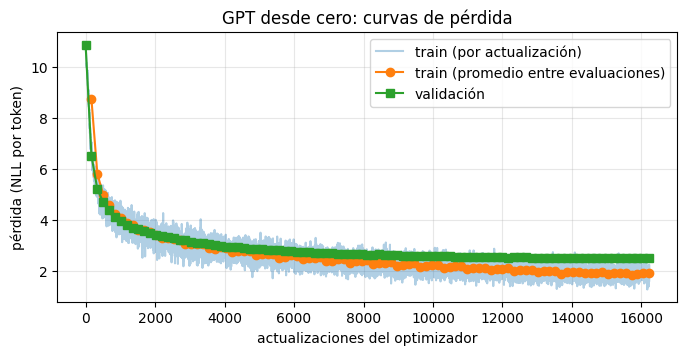

In [10]:
set_seed()
CKPT_SCRATCH = os.path.join(CKPT_DIR, 'gpt_desde_cero.pt')
gpt = GPT(**GPT_CONFIG).to(device)

hist_scratch = train_model(gpt, train_blocks, val_blocks, lr=6e-4, epochs=24, micro_batch=16, grad_accum=1,
                           ckpt_path=CKPT_SCRATCH, weight_decay=0.3, evals_per_epoch=4, log_name='gpt_desde_cero',
                           train_flat=train_flat, patience=12, exclude_embeddings=True)

# Se guarda el checkpoint final con la configuración (mejor estado según validación)
best_state = torch.load(CKPT_SCRATCH, map_location='cpu')
torch.save({'config': GPT_CONFIG, 'state_dict': best_state}, CKPT_SCRATCH)
print('Checkpoint guardado en', CKPT_SCRATCH)
plot_history(hist_scratch, 'GPT desde cero: curvas de pérdida')

del gpt, best_state
free_memory()

# 7. Finetuning de los modelos pre-entrenados

*Sección a cargo del resto del equipo* (SmolLM2-135M y SmolLM2-360M, finetuning completo).

Para integrarla con este notebook y que la comparación sea válida:
- Reutilizar `train_blocks`, `val_blocks` y `test_blocks` (sección 5) y las funciones `train_model`, `lm_loss` y
  `evaluate_nll` (sección 6). `get_logits` ya acepta modelos de Hugging Face (`AutoModelForCausalLM`).
- Agregar la carga de los modelos SmolLM2 en `load_model` y sus nombres en `CONFIG_NAMES` (sección 8): la tabla de
  resultados, la validez sintáctica y la exactitud se calculan entonces para las cinco configuraciones con el mismo código.
- Usar `generate` (sección 8) para la validez sintáctica y `show_generations` (sección 9) para los ejemplos; ambas funcionan
  con los modelos de Hugging Face (usan el KV-cache del forward, sin `model.generate()`).

# 8. Evaluación y comparación

**Perplejidad (métrica principal).** Sobre los bloques de 256 tokens del conjunto de prueba se acumula
$-\log p(x_i \mid x_{<i})$ de todos los tokens y se divide por el total $N$ antes de exponenciar
(no se promedian perplejidades por lote; no hay relleno). La evaluación se hace en fp32.

**Validez sintáctica (métrica secundaria).** Se toman 200 archivos de prueba (semilla fija). El prompt son los primeros
128 tokens del archivo y el modelo genera hasta 128 tokens más (en total 256, el contexto de entrenamiento), con
muestreo *top-p* (temperatura 0.7, p = 0.95). Si la generación no terminó con `<|endoftext|>`, se descarta la última línea
(truncada) y se verifica `prompt + continuación` con `ast.parse`, sin ejecutarlo. Como referencia se calcula la misma
métrica sobre el código real truncado de la misma forma (primeros 256 tokens), lo que indica el techo alcanzable con este
protocolo (hay bloques abiertos al truncar y archivos en Python 2).

Además se reporta la **exactitud top-1 y top-5** del siguiente token sobre las mismas posiciones que la perplejidad, y las métricas de entrenamiento (sobre un subconjunto de bloques de train del mismo tamaño que validación, sin dropout) para medir la brecha de generalización.

La generación usa la función propia de la sección 9 (se define aquí porque la evaluación la necesita).

In [11]:
@torch.no_grad()
def generate(model, prompt_ids, max_new_tokens=128, temperature=1.0, top_p=1.0, greedy=False,
             eos_id=EOS_ID, context_len=CONTEXT_LEN, generator=None):
    # Bucle autorregresivo propio (sin model.generate()):
    #   1. obtener los logits del último token, 2. convertirlos en distribución con softmax (temperatura),
    #   3. muestrear el siguiente token (top-p) o tomar el más probable, 4. concatenarlo al contexto.
    # prompt_ids: tensor [batch, T]. Para los modelos de Hugging Face se reutilizan las claves/valores de los pasos
    # anteriores (KV-cache) obtenidos del forward; el GPT propio recalcula el contexto (máximo context_len tokens).
    model.eval()
    ids = prompt_ids.to(device)
    finished = torch.zeros(ids.size(0), dtype=torch.bool, device=device)
    is_hf = not isinstance(model, GPT)
    past = None
    for _ in range(max_new_tokens):
        if is_hf:
            if past is None:
                out = model(input_ids=ids, use_cache=True)
            else:
                out = model(input_ids=ids[:, -1:], past_key_values=past, use_cache=True)
            past = out.past_key_values
            logits = out.logits[:, -1, :].float()
        else:
            logits = model(ids[:, -context_len:])[:, -1, :].float()

        if greedy:
            next_tok = logits.argmax(dim=-1, keepdim=True)
        else:
            probs = F.softmax(logits / temperature, dim=-1)
            if top_p < 1.0:
                sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
                cumulative = torch.cumsum(sorted_probs, dim=-1)
                # se conservan los tokens hasta alcanzar top_p (siempre al menos el más probable)
                remove = cumulative - sorted_probs > top_p
                sorted_probs = sorted_probs.masked_fill(remove, 0.0)
                sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
                choice = torch.multinomial(sorted_probs.cpu(), 1, generator=generator).to(device)
                next_tok = sorted_idx.gather(-1, choice)
            else:
                next_tok = torch.multinomial(probs.cpu(), 1, generator=generator).to(device)

        next_tok = next_tok.masked_fill(finished.unsqueeze(1), eos_id)  # las secuencias terminadas solo agregan EOS
        ids = torch.cat([ids, next_tok], dim=1)
        finished |= next_tok.squeeze(1) == eos_id
        if finished.all():
            break
    return ids


def decode_generation(ids, prompt_len, eos_id=EOS_ID):
    # Devuelve (texto completo, terminó_con_eos)
    ids = ids.tolist()
    gen = ids[prompt_len:]
    ended = eos_id in gen
    if ended:
        gen = gen[:gen.index(eos_id)]
    return tokenizer.decode(ids[:prompt_len] + gen), ended


def is_valid_python(src):
    try:
        ast.parse(src)
        return True
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return False


def drop_last_line(text):
    return text.rsplit('\n', 1)[0] if '\n' in text else ''

In [12]:
N_SYNTAX, PROMPT_LEN, GEN_LEN = 200, 128, 128
syntax_idx = sorted(random.Random(SEED).sample(range(len(test_tokens)), N_SYNTAX))
syntax_prompts = torch.tensor([test_tokens[i][:PROMPT_LEN] for i in syntax_idx])
assert min(len(test_tokens[i]) for i in syntax_idx) >= PROMPT_LEN


def syntax_validity(model, batch_size=50, temperature=0.7, top_p=0.95):
    gen = torch.Generator().manual_seed(SEED)
    valid, samples = [], []
    for i in range(0, N_SYNTAX, batch_size):
        out = generate(model, syntax_prompts[i:i + batch_size], max_new_tokens=GEN_LEN,
                       temperature=temperature, top_p=top_p, generator=gen).cpu()
        for row in out:
            text, ended = decode_generation(row, PROMPT_LEN)
            if not ended:
                text = drop_last_line(text)  # la última línea quedó truncada por el límite de tokens
            valid.append(is_valid_python(text))
            samples.append(text)
    return float(np.mean(valid)), samples


# Referencia: el código real truncado con el mismo protocolo (primeros 256 tokens, sin la última línea si se truncó)
ref_valid = []
for i in syntax_idx:
    toks = test_tokens[i][:PROMPT_LEN + GEN_LEN]
    ended = EOS_ID in toks
    text = tokenizer.decode([t for t in toks if t != EOS_ID])
    ref_valid.append(is_valid_python(text if ended else drop_last_line(text)))
REF_VALIDITY = float(np.mean(ref_valid))
print(f'Validez sintáctica del código real truncado (referencia): {REF_VALIDITY:.1%}')

Validez sintáctica del código real truncado (referencia): 52.0%


In [13]:
def load_model(config_name):
    # Al integrar la sección 7, agregar aquí la carga de los modelos SmolLM2 (pre-entrenados y finetuned)
    if config_name == 'GPT desde cero':
        ckpt = torch.load(CKPT_SCRATCH, map_location='cpu')
        model = GPT(**ckpt['config'])
        model.load_state_dict(ckpt['state_dict'])
        return model.to(device)
    raise ValueError(config_name)


@torch.no_grad()
def evaluate_accuracy(model, blocks, batch_size=16):
    # Exactitud top-1 / top-5 del siguiente token, sobre las mismas posiciones que la perplejidad
    model.eval()
    top1, top5, n = 0, 0, 0
    for i in range(0, len(blocks), batch_size):
        x = blocks[i:i + batch_size].to(device)
        logits, y = get_logits(model, x)[:, :-1].float(), x[:, 1:]
        best = logits.topk(5, dim=-1).indices
        top1 += (best[..., 0] == y).sum().item()
        top5 += (best == y.unsqueeze(-1)).any(-1).sum().item()
        n += y.numel()
    return top1 / n, top5 / n


# Bloques de train para medir la brecha (mismo número que validación, repartidos a lo largo del split)
train_eval_blocks = train_blocks[torch.linspace(0, len(train_blocks) - 1, len(val_blocks)).long()]

CONFIG_NAMES = ['GPT desde cero']
results, splits_rows, syntax_samples = [], [], {}
for name in CONFIG_NAMES:
    t0 = time.time()
    model = load_model(name)
    n_params = sum(p.numel() for p in model.parameters())
    metrics = {}
    for split, blocks in [('train', train_eval_blocks), ('validación', val_blocks), ('prueba', test_blocks)]:
        nll, n_tok = evaluate_nll(model, blocks, use_amp=False)  # perplejidad en fp32
        top1, top5 = evaluate_accuracy(model, blocks)
        metrics[split] = {'NLL': nll / n_tok, 'PPL': math.exp(nll / n_tok), 'top-1': top1, 'top-5': top5, 'tokens': n_tok}
        splits_rows.append({'configuración': name, 'partición': split, **metrics[split]})
    set_seed()
    validity, samples = syntax_validity(model)
    syntax_samples[name] = samples
    results.append({'configuración': name, 'parámetros': n_params, 'tokens evaluados': metrics['prueba']['tokens'],
                    'NLL prueba': metrics['prueba']['NLL'], 'PPL prueba': metrics['prueba']['PPL'],
                    'PPL validación': metrics['validación']['PPL'], 'exactitud top-1 prueba': metrics['prueba']['top-1'],
                    'exactitud top-5 prueba': metrics['prueba']['top-5'], 'validez sintáctica': validity})
    log(f'{name:28s} | PPL prueba {metrics["prueba"]["PPL"]:8.2f} | top-1 {metrics["prueba"]["top-1"]:.1%} | '
        f'validez {validity:.1%} | {time.time() - t0:.0f}s')
    del model
    free_memory()

results_df = pd.DataFrame(results).set_index('configuración')
results_df.to_csv(os.path.join(RESULTS_DIR, 'resultados_prueba.csv'))
with open(os.path.join(RESULTS_DIR, 'syntax_samples.json'), 'w') as f:
    json.dump(syntax_samples, f)
results_df.style.format({'parámetros': '{:,}', 'tokens evaluados': '{:,}', 'NLL prueba': '{:.4f}', 'PPL prueba': '{:.2f}',
                         'PPL validación': '{:.2f}', 'exactitud top-1 prueba': '{:.1%}', 'exactitud top-5 prueba': '{:.1%}',
                         'validez sintáctica': '{:.1%}'})

GPT desde cero               | PPL prueba    11.98 | top-1 58.0% | validez 46.5% | 2472s


,parámetros,tokens evaluados,NLL prueba,PPL prueba,PPL validación,exactitud top-1 prueba,exactitud top-5 prueba,validez sintáctica
configuración,,,,,,,,
GPT desde cero,"29,620,224","345,780",2.4829,11.98,12.14,58.0%,75.8%,46.5%


Brecha validación − train: +0.906 nats | PPL prueba / validación: -1.3% | validez sintáctica 46.5% (código real truncado: 52.0%)


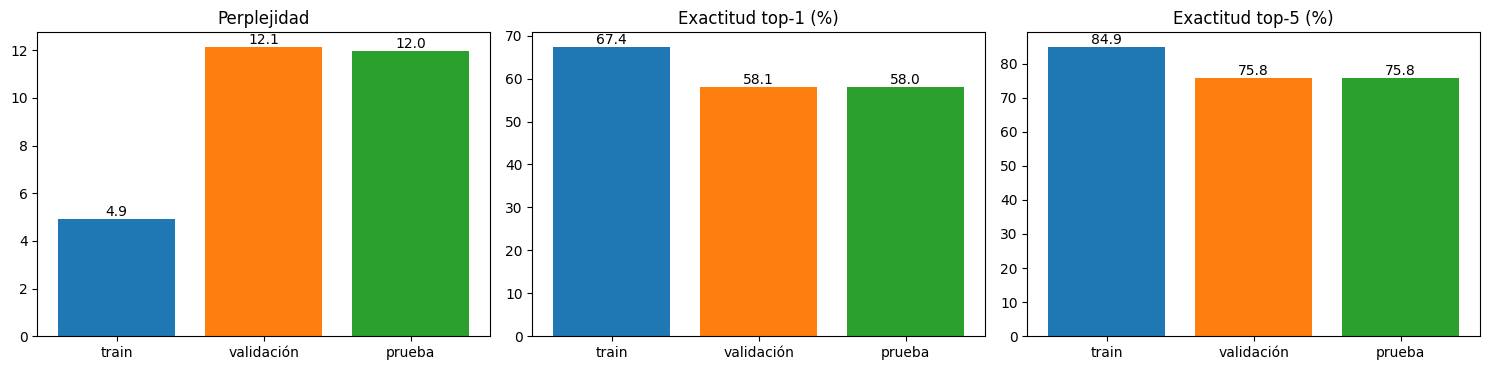

In [14]:
# Métricas por partición: la diferencia entre train y validación/prueba mide la memorización
splits_df = pd.DataFrame(splits_rows).set_index(['configuración', 'partición'])
display(splits_df.style.format({'NLL': '{:.4f}', 'PPL': '{:.2f}', 'top-1': '{:.1%}', 'top-5': '{:.1%}', 'tokens': '{:,}'}))

m = splits_df.loc['GPT desde cero']
print(f"Brecha validación − train: {m.loc['validación', 'NLL'] - m.loc['train', 'NLL']:+.3f} nats | "
      f"PPL prueba / validación: {m.loc['prueba', 'PPL'] / m.loc['validación', 'PPL'] - 1:+.1%} | "
      f"validez sintáctica {results_df.loc['GPT desde cero', 'validez sintáctica']:.1%} "
      f"(código real truncado: {REF_VALIDITY:.1%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(3)
for ax, col, title, scale in [(axes[0], 'PPL', 'Perplejidad', 1), (axes[1], 'top-1', 'Exactitud top-1 (%)', 100),
                              (axes[2], 'top-5', 'Exactitud top-5 (%)', 100)]:
    bars = ax.bar(x, m[col].values * scale, color=['tab:blue', 'tab:orange', 'tab:green'])
    ax.bar_label(bars, fmt='%.1f')
    ax.set_xticks(x, m.index)
    ax.set_title(title)
plt.tight_layout(); plt.show()

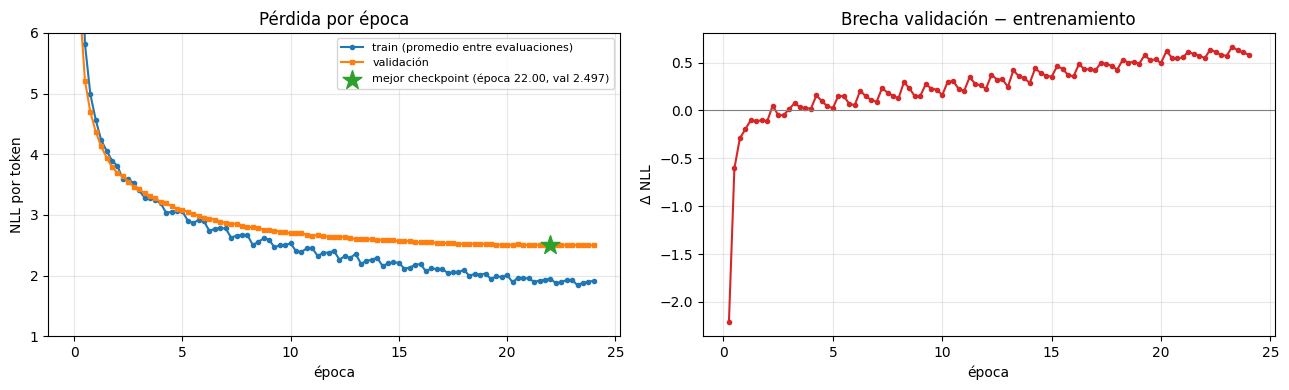

Épocas entrenadas: 24.00 | early stopping: False | mejor val loss 2.4966 (PPL 12.14) | tiempo 23.3 min


In [15]:
# Curva de la función de costo por época y brecha validación − entrenamiento (sobreajuste)
h = hist_scratch
updates_per_epoch = (len(train_flat) // CONTEXT_LEN - 1) // 16
ev = np.array(h['eval_update']) / updates_per_epoch
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ev[1:], h['eval_train_loss'][1:], 'o-', ms=3, label='train (promedio entre evaluaciones)')
axes[0].plot(ev, h['val_loss'], 's-', ms=3, label='validación')
best = int(np.argmin(h['val_loss']))
axes[0].scatter([ev[best]], [h['val_loss'][best]], marker='*', s=200, color='tab:green', zorder=5,
                label=f'mejor checkpoint (época {ev[best]:.2f}, val {h["val_loss"][best]:.3f})')
axes[0].set(title='Pérdida por época', xlabel='época', ylabel='NLL por token', ylim=(1, 6))
axes[1].plot(ev[1:], np.array(h['val_loss'][1:]) - np.array(h['eval_train_loss'][1:]), 'o-', ms=3, color='tab:red')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set(title='Brecha validación − entrenamiento', xlabel='época', ylabel='Δ NLL')
axes[0].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Épocas entrenadas: {ev[-1]:.2f} | early stopping: {h['stopped_early']} | mejor val loss {h['best_val_loss']:.4f} "
      f"(PPL {math.exp(h['best_val_loss']):.2f}) | tiempo {h['train_time_s'] / 60:.1f} min")

### Análisis

FALTA 

# 9. Generación de ejemplos

La función `generate` definida en la sección 8 implementa desde cero el bucle autorregresivo para todas las configuraciones:
en cada paso se obtienen los logits del modelo para la última posición, se dividen por la temperatura y se convierten en
una distribución con softmax; luego se aplica *top-p* (se ordenan las probabilidades, se conservan los tokens cuya
probabilidad acumulada alcanza p y se renormaliza) y se muestrea el siguiente token, que se concatena al contexto. Para los
modelos de Hugging Face se aprovecha el KV-cache que devuelve el forward (solo se procesa el último token en cada paso);
el GPT propio recibe como máximo los últimos 256 tokens. No se usa `model.generate()`.

Se generan 4 ejemplos con el modelo desde cero. Al integrar la sección 7, basta llamar `show_generations` con el nombre de cada modelo para obtener los ejemplos con los mismos prompts.

In [16]:
GEN_PROMPTS = [
    'def fibonacci(n):\n    # Return the n-th Fibonacci number',
    'import os\n\n\ndef list_python_files(directory):',
    'class Stack(object):\n    def __init__(self):',
    'import numpy as np\n\n\ndef normalize(x):',
]


def show_generations(name, temperature=0.4, top_p=0.9, max_new_tokens=120):
    model = load_model(name)
    gen = torch.Generator().manual_seed(SEED)
    print('=' * 30, name, '=' * 30)
    for k, prompt in enumerate(GEN_PROMPTS, 1):
        ids = torch.tensor([tokenizer(prompt)['input_ids']])
        out = generate(model, ids, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p, generator=gen)
        text, ended = decode_generation(out[0].cpu(), ids.size(1))
        checked = text if ended else drop_last_line(text)
        print(f'--- Ejemplo {k} | sintácticamente válido: {is_valid_python(checked)} ---')
        print(text)
        print()
    del model
    free_memory()

In [17]:
show_generations('GPT desde cero')

============================== GPT desde cero ==============================
--- Ejemplo 1 | sintácticamente válido: False ---
def fibonacci(n):
    # Return the n-th Fibonacci number of the number of the number of the number of the number of the number of the number
    # the number of the number of the number of the number of the number of the number
    # number of the number of the number of the number of the number of the number of the number
    # number of the number of the number of the number of the number of the number
    # number of the number of the number of the number of the number
    number = number of the number of the number of the number
    # number of the number of the number of the number
    number of the

--- Ejemplo 2 | sintácticamente válido: True ---
import os


def list_python_files(directory):
    """
    Return the list of files to the current directory.
    """
    return os.path.abspath(directory)


def list_python_files(directory):
    """
    Return t

**Comentario de los ejemplos.**
FALTA

# 10. Conclusiones

FALTA